# HCMC Weather Forecasting (1h / 3h / 6h)

Self-supervised forecasting: features from the past 24 h of hourly observations at issue time *t*,
targets are the same dataset's values at *t+1h, t+3h, t+6h*.

- **Temperature**: LightGBM regressor (MAE, RMSE)
- **Rain** (`precipitation > 0.1 mm` in the hour ending at t+h): LightGBM classifier (Accuracy, Precision, Recall, F1)
- Baselines: persistence, climatology (train-period mean by target hour x month)

Data source: `backend/data/weather.db`, table `hourly_weather` (cleaned copy of the Open-Meteo Excel export; the original Excel is not modified).
Feature engineering lives in `backend/ai_model.py::build_features` and is shared with the inference code.

In [1]:
import os, sys, json, sqlite3, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
                             precision_score, recall_score, f1_score, brier_score_loss)

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 160)
SEED = 42
np.random.seed(SEED)

ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
BACKEND = os.path.join(ROOT, 'backend')
DB_PATH = os.path.join(BACKEND, 'data', 'weather.db')
MODEL_DIR = os.path.join(BACKEND, 'models')
FIG_DIR = os.path.join(ROOT, 'notebooks', 'figures')
os.makedirs(MODEL_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

sys.path.insert(0, BACKEND)
import ai_model
importlib.reload(ai_model)
from ai_model import build_features, build_targets, feature_columns, HORIZONS, RAIN_THRESHOLD_MM
print('lightgbm', lgb.__version__, '| pandas', pd.__version__)

lightgbm 4.7.0 | pandas 3.0.6


## 1. EDA
### 1.1 Load and audit

In [2]:
with sqlite3.connect(DB_PATH) as con:
    df = pd.read_sql('SELECT * FROM hourly_weather ORDER BY timestamp', con)
df['timestamp'] = pd.to_datetime(df['timestamp'])
print('shape:', df.shape)
print(df.dtypes.to_string())
gaps = (df['timestamp'].diff().dropna() != pd.Timedelta(hours=1)).sum()
print(f"range: {df['timestamp'].min()} -> {df['timestamp'].max()}")
print(f"monotonic: {df['timestamp'].is_monotonic_increasing}, duplicate timestamps: {df['timestamp'].duplicated().sum()}, non-1h gaps: {gaps}")

shape: (85673, 16)
timestamp                    datetime64[us]
temperature                         float64
humidity                            float64
dew_point                           float64
apparent_temperature                float64
precipitation_probability           float64
precipitation                       float64
rain                                float64
weather_code                        float64
visibility                          float64
cloud_cover                         float64
surface_pressure                    float64
pressure_msl                        float64
wind_speed                          float64
wind_direction                      float64
wind_gusts                          float64
range: 2017-01-01 07:00:00 -> 2026-10-10 23:00:00
monotonic: True, duplicate timestamps: 0, non-1h gaps: 0


### 1.2 Missing values and ranges

In [3]:
miss = df.isna().mean().mul(100).round(2).rename('missing_%')
print(miss[miss > 0].to_string())
print()
print(df.describe().T[['mean', 'min', 'max']].round(2).to_string())

precipitation_probability    74.91
visibility                   43.20

                                          mean                  min                  max
timestamp                  2021-11-21 03:00:00  2017-01-01 07:00:00  2026-10-10 23:00:00
temperature                          27.595232                 17.9                 39.4
humidity                             78.048008                 21.0                100.0
dew_point                            22.983779                  8.7                 27.4
apparent_temperature                 32.104528                 17.2                 44.2
precipitation_probability            33.425228                  0.0                100.0
precipitation                          0.25109                  0.0                 22.3
rain                                  0.235644                  0.0                 22.3
weather_code                         16.658469                  0.0                 96.0
visibility                        22276

`precipitation_probability` and `visibility` are mostly missing, so they are **not** used as features. Every other column is complete. No imputation is needed.

### 1.3 Temperature and precipitation over time

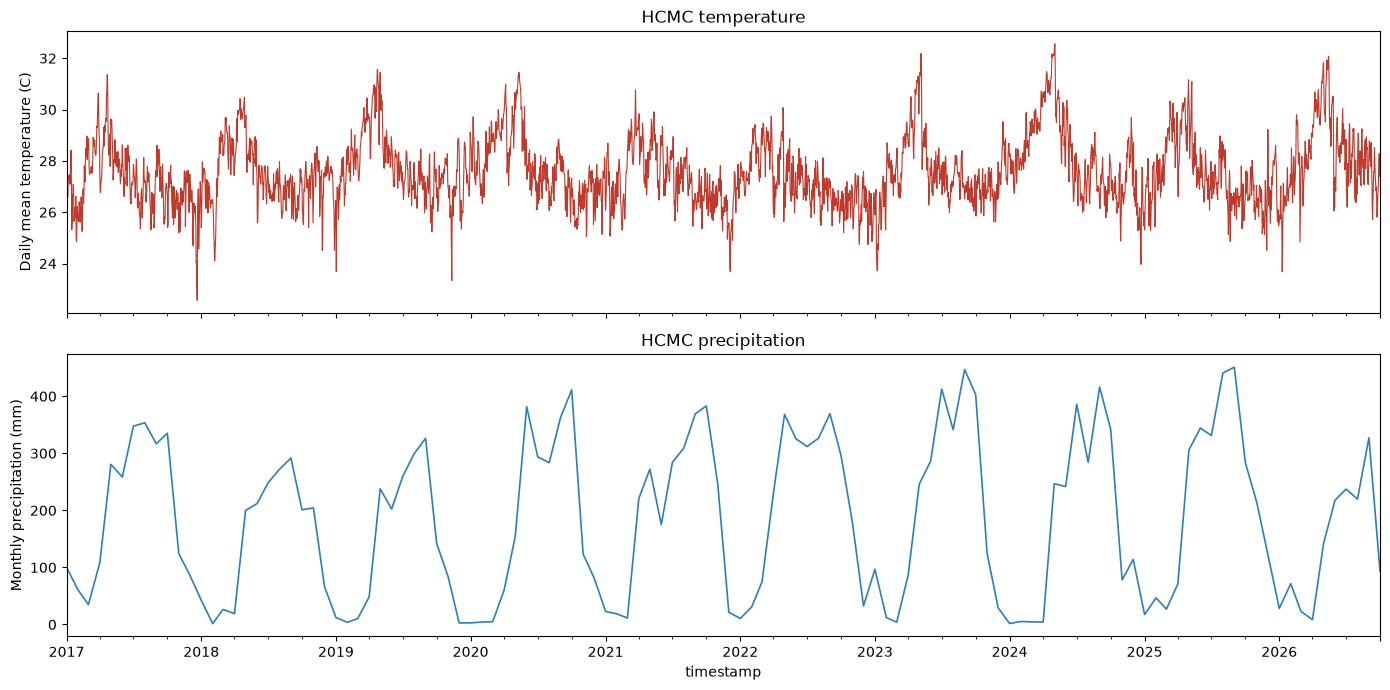

In [4]:
s = df.set_index('timestamp')
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
s['temperature'].resample('D').mean().plot(ax=axes[0], color='#c0392b', lw=0.8)
axes[0].set_ylabel('Daily mean temperature (C)'); axes[0].set_title('HCMC temperature')
s['precipitation'].resample('MS').sum().plot(ax=axes[1], kind='line', color='#2c7fb8', lw=1.2)
axes[1].set_ylabel('Monthly precipitation (mm)'); axes[1].set_title('HCMC precipitation')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'timeseries.png'), dpi=120); plt.show()

### 1.4 Hourly and monthly patterns

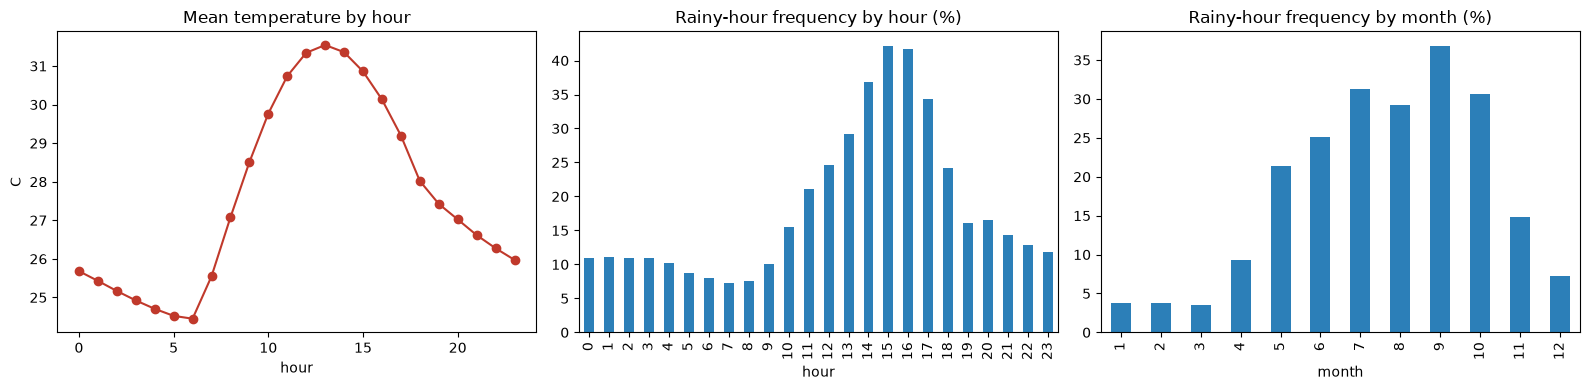

Overall rainy-hour rate: 0.182
month
1     0.038
2     0.038
3     0.036
4     0.093
5     0.214
6     0.251
7     0.313
8     0.292
9     0.368
10    0.306
11    0.148
12    0.072


In [5]:
tmp = df.assign(hour=df.timestamp.dt.hour, month=df.timestamp.dt.month,
                rain=(df.precipitation > RAIN_THRESHOLD_MM).astype(int))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
tmp.groupby('hour')['temperature'].mean().plot(ax=axes[0], marker='o', color='#c0392b')
axes[0].set_title('Mean temperature by hour'); axes[0].set_ylabel('C')
tmp.groupby('hour')['rain'].mean().mul(100).plot(ax=axes[1], kind='bar', color='#2c7fb8')
axes[1].set_title('Rainy-hour frequency by hour (%)')
tmp.groupby('month')['rain'].mean().mul(100).plot(ax=axes[2], kind='bar', color='#2c7fb8')
axes[2].set_title('Rainy-hour frequency by month (%)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'patterns.png'), dpi=120); plt.show()
print('Overall rainy-hour rate: %.3f' % tmp['rain'].mean())
print(tmp.groupby('month')['rain'].mean().round(3).to_string())

## 2. Feature engineering

`build_features` (from `backend/ai_model.py`) produces, for each issue time *t*:
- current observations at *t* (temperature, humidity, dew point, apparent temp, precipitation, weather code, cloud cover, pressures, wind speed/gusts, wind direction as sin/cos)
- lags *t-1, t-3, t-6, t-12, t-24 h* for temperature, humidity, precipitation, pressure_msl, wind speed, cloud cover
- trailing (not centered) 3/6/24 h rolling mean and std for temperature, humidity, precipitation
- time features: hour, day_of_week, month, is_rainy_season (May-Nov), cyclical hour/month
- tendencies: 1h temperature change, 3h pressure tendency, rainy hours in last 24h

Targets come from `build_targets`: temperature at *t+h* and `precipitation(t+h) > 0.1 mm`.

In [6]:
FEATURES = feature_columns()
X_all = build_features(df)
Y_all = build_targets(df)
assert list(X_all.columns) == FEATURES
data = pd.concat([df[['timestamp']], X_all, Y_all], axis=1)
before = len(data)
data = data.dropna(subset=FEATURES + list(Y_all.columns)).reset_index(drop=True)
print(f'{len(FEATURES)} features; rows {before} -> {len(data)} after dropping warm-up (24h) and tail (6h)')

72 features; rows 85673 -> 85643 after dropping warm-up (24h) and tail (6h)


## 3. Chronological split
- Train: 2017 - 2023, Validation: 2024 (early stopping, rain threshold), Test: 2025-01-01 -> 2026-10-10
- No shuffling. The last 6 issue hours of train and of validation are purged so that no target crosses into the next split.

In [7]:
ts = data['timestamp']
train = data[(ts < '2024-01-01') & (ts <= pd.Timestamp('2024-01-01') - pd.Timedelta(hours=7))]
val = data[(ts >= '2024-01-01') & (ts <= pd.Timestamp('2025-01-01') - pd.Timedelta(hours=7))]
test = data[ts >= '2025-01-01']
for n, d in [('train', train), ('val', val), ('test', test)]:
    print(f"{n:5s} {len(d):6d} rows  {d.timestamp.min()} -> {d.timestamp.max()}  rain_1h rate {d['rain_target_1h'].mean():.3f}")
Xtr, Xva, Xte = train[FEATURES], val[FEATURES], test[FEATURES]

train  61307 rows  2017-01-02 07:00:00 -> 2023-12-31 17:00:00  rain_1h rate 0.187
val     8778 rows  2024-01-01 00:00:00 -> 2024-12-31 17:00:00  rain_1h rate 0.153
test   15546 rows  2025-01-01 00:00:00 -> 2026-10-10 17:00:00  rain_1h rate 0.179


## 4. Baselines
**Persistence**: temperature(t+h) = temperature(t); rain(t+h) = rain(t).

**Climatology**: train-period mean temperature and rain frequency for the target's (hour, month); rain predicted when frequency > 0.5.

In [8]:
clim_src = df[df.timestamp < '2024-01-01'].assign(hour=lambda d: d.timestamp.dt.hour, month=lambda d: d.timestamp.dt.month,
                                                  rain=lambda d: (d.precipitation > RAIN_THRESHOLD_MM).astype(float))
clim = clim_src.groupby(['hour', 'month']).agg(clim_temp=('temperature', 'mean'), clim_rain=('rain', 'mean'))

def clim_lookup(d, h):
    tt = d['timestamp'] + pd.Timedelta(hours=h)
    idx = pd.MultiIndex.from_arrays([tt.dt.hour, tt.dt.month])
    return clim.reindex(idx).reset_index(drop=True).set_index(d.index)

def reg_metrics(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': float(np.sqrt(mean_squared_error(y, p)))}

def clf_metrics(y, yhat, prob=None):
    m = {'Accuracy': accuracy_score(y, yhat), 'Precision': precision_score(y, yhat, zero_division=0),
         'Recall': recall_score(y, yhat, zero_division=0), 'F1': f1_score(y, yhat, zero_division=0)}
    m['Brier'] = brier_score_loss(y, prob) if prob is not None else np.nan
    return m

temp_rows, rain_rows = [], []
for h in HORIZONS:
    yt, yr = test[f'temp_target_{h}h'], test[f'rain_target_{h}h'].astype(int)
    temp_rows.append({'Horizon': f'{h}h', 'Model': 'Persistence', **reg_metrics(yt, test['temperature'])})
    rain_rows.append({'Horizon': f'{h}h', 'Model': 'Persistence',
                      **clf_metrics(yr, (test['precipitation'] > RAIN_THRESHOLD_MM).astype(int))})
    c = clim_lookup(test, h)
    temp_rows.append({'Horizon': f'{h}h', 'Model': 'Climatology', **reg_metrics(yt, c['clim_temp'])})
    rain_rows.append({'Horizon': f'{h}h', 'Model': 'Climatology',
                      **clf_metrics(yr, (c['clim_rain'] > 0.5).astype(int), c['clim_rain'])})
print(pd.DataFrame(temp_rows).round(3).to_string(index=False)); print()
print(pd.DataFrame(rain_rows).round(3).to_string(index=False))

Horizon       Model   MAE  RMSE
     1h Persistence 0.758 1.072
     1h Climatology 1.103 1.453
     3h Persistence 1.972 2.571
     3h Climatology 1.103 1.453
     6h Persistence 3.392 4.193
     6h Climatology 1.102 1.453

Horizon       Model  Accuracy  Precision  Recall    F1  Brier
     1h Persistence     0.872      0.645   0.644 0.645    NaN
     1h Climatology     0.835      0.578   0.304 0.399  0.120
     3h Persistence     0.793      0.424   0.424 0.424    NaN
     3h Climatology     0.835      0.578   0.304 0.399  0.120
     6h Persistence     0.757      0.324   0.324 0.324    NaN
     6h Climatology     0.835      0.578   0.304 0.399  0.121


## 5. LightGBM
### 5.1 Temperature regressors (early stopping on 2024)

In [9]:
reg_params = dict(objective='regression', metric='mae', learning_rate=0.05, num_leaves=31,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=5, min_data_in_leaf=50,
                  seed=SEED, deterministic=True, verbose=-1)
temp_models, test_pred = {}, {}
for h in HORIZONS:
    y = f'temp_target_{h}h'
    m = lgb.train(reg_params, lgb.Dataset(Xtr, train[y]), num_boost_round=2000,
                  valid_sets=[lgb.Dataset(Xva, val[y])], callbacks=[lgb.early_stopping(100, verbose=False)])
    temp_models[h] = m
    p = m.predict(Xte, num_iteration=m.best_iteration)
    test_pred[f'temp_{h}h'] = p
    temp_rows.append({'Horizon': f'{h}h', 'Model': 'LightGBM', **reg_metrics(test[y], p)})
    print(f'{h}h: best_iter={m.best_iteration}, val MAE={m.best_score["valid_0"]["l1"]:.3f}')

1h: best_iter=514, val MAE=0.320


3h: best_iter=440, val MAE=0.542


6h: best_iter=584, val MAE=0.654


### 5.2 Rain classifiers
No class re-weighting, so outputs stay usable as probabilities. The decision threshold is chosen on **validation** (max F1) and then applied unchanged to test.

In [10]:
clf_params = dict(objective='binary', metric='binary_logloss', learning_rate=0.05, num_leaves=31,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=5, min_data_in_leaf=50,
                  seed=SEED, deterministic=True, verbose=-1)
rain_models, rain_thresholds = {}, {}
grid = np.round(np.arange(0.10, 0.71, 0.02), 2)
for h in HORIZONS:
    y = f'rain_target_{h}h'
    m = lgb.train(clf_params, lgb.Dataset(Xtr, train[y]), num_boost_round=2000,
                  valid_sets=[lgb.Dataset(Xva, val[y])], callbacks=[lgb.early_stopping(100, verbose=False)])
    rain_models[h] = m
    pv = m.predict(Xva, num_iteration=m.best_iteration)
    thr = float(grid[np.argmax([f1_score(val[y], pv > t) for t in grid])])
    rain_thresholds[h] = thr
    pt = m.predict(Xte, num_iteration=m.best_iteration)
    test_pred[f'rain_{h}h'] = pt
    yt = test[y].astype(int)
    rain_rows.append({'Horizon': f'{h}h', 'Model': 'LightGBM (thr@0.5)', **clf_metrics(yt, (pt > 0.5).astype(int), pt)})
    rain_rows.append({'Horizon': f'{h}h', 'Model': f'LightGBM (thr@{thr:.2f} val-tuned)', **clf_metrics(yt, (pt > thr).astype(int), pt)})
    print(f'{h}h: best_iter={m.best_iteration}, val-tuned threshold={thr:.2f}')

1h: best_iter=211, val-tuned threshold=0.46


3h: best_iter=142, val-tuned threshold=0.36


6h: best_iter=189, val-tuned threshold=0.32


## 6. Results on the test set (2025-01-01 -> 2026-10-10)

In [11]:
temp_res = pd.DataFrame(temp_rows).sort_values(['Horizon', 'Model']).reset_index(drop=True)
rain_res = pd.DataFrame(rain_rows).sort_values(['Horizon', 'Model']).reset_index(drop=True)
print('TEMPERATURE (C)'); print(temp_res.round(3).to_string(index=False)); print()
print('RAIN (precipitation > 0.1 mm)'); print(rain_res.round(3).to_string(index=False))

TEMPERATURE (C)
Horizon       Model   MAE  RMSE
     1h Climatology 1.103 1.453
     1h    LightGBM 0.372 0.615
     1h Persistence 0.758 1.072
     3h Climatology 1.103 1.453
     3h    LightGBM 0.644 0.919
     3h Persistence 1.972 2.571
     6h Climatology 1.102 1.453
     6h    LightGBM 0.770 1.059
     6h Persistence 3.392 4.193

RAIN (precipitation > 0.1 mm)
Horizon                         Model  Accuracy  Precision  Recall    F1  Brier
     1h                   Climatology     0.835      0.578   0.304 0.399  0.120
     1h LightGBM (thr@0.46 val-tuned)     0.883      0.696   0.618 0.655  0.083
     1h            LightGBM (thr@0.5)     0.884      0.717   0.585 0.644  0.083
     1h                   Persistence     0.872      0.645   0.644 0.645    NaN
     3h                   Climatology     0.835      0.578   0.304 0.399  0.120
     3h LightGBM (thr@0.36 val-tuned)     0.829      0.523   0.547 0.535  0.109
     3h            LightGBM (thr@0.5)     0.843      0.605   0.364 0.455 

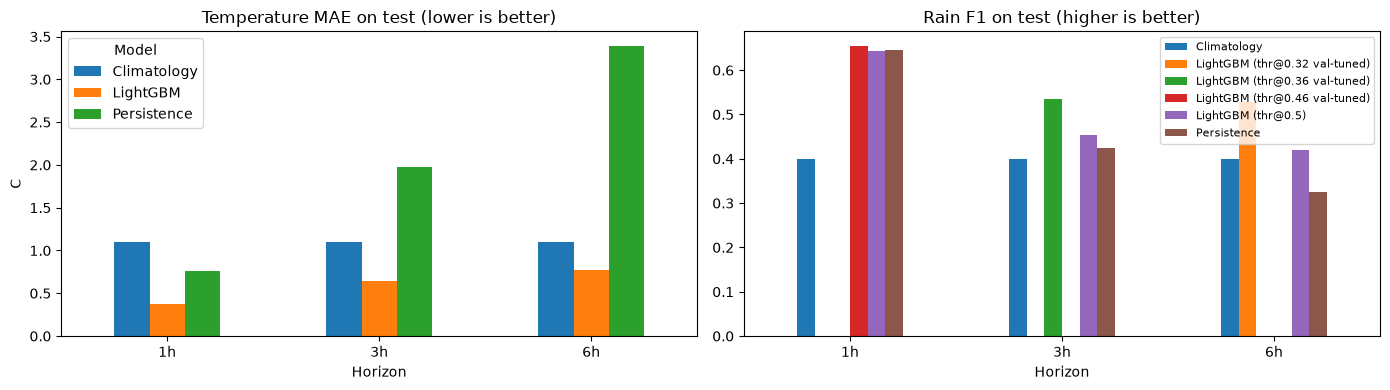

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
temp_res.pivot(index='Horizon', columns='Model', values='MAE').plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Temperature MAE on test (lower is better)'); axes[0].set_ylabel('C')
rain_res.pivot(index='Horizon', columns='Model', values='F1').plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Rain F1 on test (higher is better)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'results.png'), dpi=120); plt.show()

## 7. Feature importance (gain, 1h models)

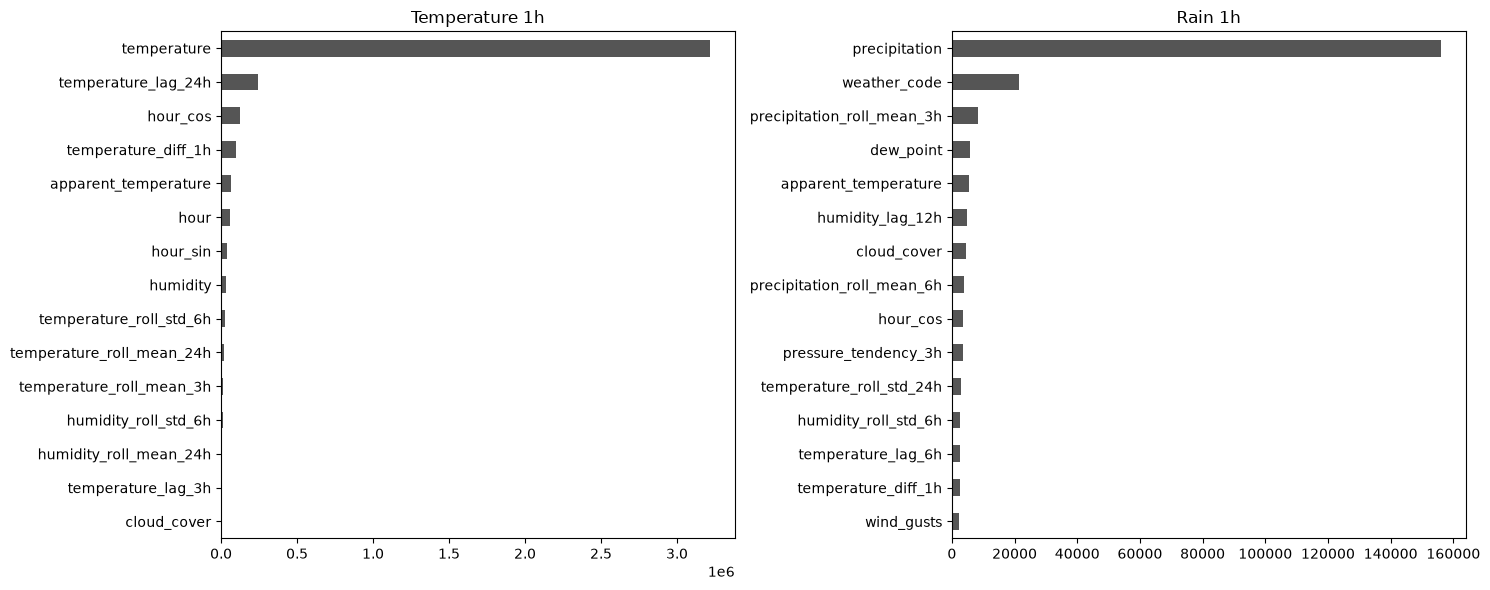

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, m, title in [(axes[0], temp_models[1], 'Temperature 1h'), (axes[1], rain_models[1], 'Rain 1h')]:
    imp = pd.Series(m.feature_importance('gain'), index=FEATURES).sort_values().tail(15)
    imp.plot(kind='barh', ax=ax, color='#555'); ax.set_title(title)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'feature_importance.png'), dpi=120); plt.show()

## 8. Save models

In [14]:
MODEL_VERSION = 'lgbm-hcmc-v2-' + pd.Timestamp('today').strftime('%Y%m%d')
for h in HORIZONS:
    # Save boosters truncated to their best iteration so predict() needs no extra args
    t_m = lgb.Booster(model_str=temp_models[h].model_to_string(num_iteration=temp_models[h].best_iteration))
    r_m = lgb.Booster(model_str=rain_models[h].model_to_string(num_iteration=rain_models[h].best_iteration))
    joblib.dump(t_m, os.path.join(MODEL_DIR, f'temperature_model_{h}h.pkl'))
    joblib.dump(r_m, os.path.join(MODEL_DIR, f'rain_model_{h}h.pkl'))
with open(os.path.join(MODEL_DIR, 'feature_columns.json'), 'w', encoding='utf-8') as f:
    json.dump(FEATURES, f, indent=2)
meta = {'model_version': MODEL_VERSION, 'data': 'backend/data/weather.db:hourly_weather',
        'train': [str(train.timestamp.min()), str(train.timestamp.max())],
        'val': [str(val.timestamp.min()), str(val.timestamp.max())],
        'test': [str(test.timestamp.min()), str(test.timestamp.max())],
        'rain_threshold_mm': RAIN_THRESHOLD_MM,
        'rain_decision_threshold': {f'{h}h': rain_thresholds[h] for h in HORIZONS},
        'test_metrics_temperature': temp_res.round(4).to_dict('records'),
        'test_metrics_rain': rain_res.round(4).to_dict('records')}
with open(os.path.join(MODEL_DIR, 'model_metadata.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=2)
print(MODEL_VERSION); print(sorted(os.listdir(MODEL_DIR)))

lgbm-hcmc-v2-20261015
['feature_columns.json', 'model_metadata.json', 'rain_model_1h.pkl', 'rain_model_3h.pkl', 'rain_model_6h.pkl', 'temperature_model_1h.pkl', 'temperature_model_3h.pkl', 'temperature_model_6h.pkl']


## 9. Train/serve consistency: `predict_from_history` vs notebook predictions
For several test timestamps, pass only the 48 hourly rows ending at *t* to the inference code (loading the saved .pkl files) and compare with the notebook's test-set predictions for the same row.

In [15]:
importlib.reload(ai_model)
rng = np.random.default_rng(SEED)
pos = np.sort(rng.choice(len(test), 6, replace=False))
rows, max_diff = [], 0.0
for p in pos:
    t = test['timestamp'].iloc[p]
    hist = df[df.timestamp <= t].tail(48)
    out = ai_model.predict_from_history(hist)
    for h in HORIZONS:
        a_t, b_t = out['predictions'][f'{h}h']['temperature'], test_pred[f'temp_{h}h'][p]
        a_r, b_r = out['predictions'][f'{h}h']['rain_probability'], test_pred[f'rain_{h}h'][p]
        max_diff = max(max_diff, abs(a_t - b_t), abs(a_r - b_r))
        rows.append({'issued_at': out['issued_at'], 'h': h, 'temp_serve': a_t, 'temp_nb': round(b_t, 2),
                     'rain_p_serve': a_r, 'rain_p_nb': round(b_r, 4)})
print(pd.DataFrame(rows).to_string(index=False))
print(f'max |serve - notebook| = {max_diff:.5f} (serve output is rounded to 2/4 decimals)')
assert max_diff < 0.01
print(json.dumps(out, indent=2))

          issued_at  h  temp_serve  temp_nb  rain_p_serve  rain_p_nb
2025-02-27T19:00:00  1       27.99    27.99        0.0011     0.0011
2025-02-27T19:00:00  3       26.79    26.79        0.0055     0.0055
2025-02-27T19:00:00  6       25.95    25.95        0.0028     0.0028
2025-10-08T11:00:00  1       31.12    31.12        0.5288     0.5288
2025-10-08T11:00:00  3       29.64    29.64        0.6868     0.6868
2025-10-08T11:00:00  6       27.32    27.32        0.5001     0.5001
2025-10-12T05:00:00  1       23.92    23.92        0.1072     0.1072
2025-10-12T05:00:00  3       26.28    26.28        0.2244     0.2244
2025-10-12T05:00:00  6       28.66    28.66        0.4141     0.4141
2026-02-28T22:00:00  1       25.29    25.29        0.0023     0.0023
2026-02-28T22:00:00  3       24.68    24.68        0.0184     0.0184
2026-02-28T22:00:00  6       24.28    24.28        0.0379     0.0379
2026-05-17T04:00:00  1       26.17    26.17        0.7795     0.7795
2026-05-17T04:00:00  3       27.65

## 10. Leakage checks
1. **Future-perturbation test**: randomise every value *after* issue time *t* and confirm all features at *t* are unchanged.
2. **Column audit**: no target-derived or forecast-product columns are in the feature list.
3. **Split purge**: no train/val target timestamp falls in the next split.

In [16]:
bad = 0
for p in pos:
    t = test['timestamp'].iloc[p]
    win = df[(df.timestamp > t - pd.Timedelta(hours=48)) & (df.timestamp <= t + pd.Timedelta(hours=12))].reset_index(drop=True)
    f0 = build_features(win)
    i = win.index[win.timestamp == t][0]
    pert = win.copy()
    num = [c for c in pert.columns if c != 'timestamp']
    pert.loc[i + 1:, num] = rng.normal(size=(len(pert) - i - 1, len(num))) * 100
    f1 = build_features(pert)
    bad += int(not np.allclose(f0.loc[i, FEATURES].astype(float), f1.loc[i, FEATURES].astype(float), equal_nan=True))
print('timestamps whose features changed when the future was perturbed:', bad, '/', len(pos))
forbidden = ['target', 'precipitation_probability', 'visibility', 'rain']  # 'rain' column duplicates precipitation
print('forbidden substrings in features:', [f for f in FEATURES if any(s in f for s in forbidden) and f != 'is_rainy_season'])
print('max train target time:', train.timestamp.max() + pd.Timedelta(hours=6), '| max val target time:', val.timestamp.max() + pd.Timedelta(hours=6))

timestamps whose features changed when the future was perturbed: 0 / 6
forbidden substrings in features: []
max train target time: 2023-12-31 23:00:00 | max val target time: 2024-12-31 23:00:00


## 11. Summary

All numbers are from the executed test-set outputs above (test = 2025-01-01 00:00 to 2026-10-10 17:00, 15,546 issue hours; train 2017-2023, val 2024).

**Temperature (MAE / RMSE, C)**

| Horizon | Persistence | Climatology | LightGBM |
|---|---|---|---|
| 1h | 0.758 / 1.072 | 1.103 / 1.453 | **0.372 / 0.615** |
| 3h | 1.972 / 2.571 | 1.103 / 1.453 | **0.644 / 0.919** |
| 6h | 3.392 / 4.193 | 1.102 / 1.453 | **0.770 / 1.059** |

LightGBM beats both baselines at every horizon.

**Rain (precipitation > 0.1 mm), F1 (Accuracy)**

| Horizon | Persistence | Climatology | LightGBM thr 0.5 | LightGBM val-tuned thr |
|---|---|---|---|---|
| 1h | 0.645 (0.872) | 0.399 (0.835) | 0.644 (0.884) | **0.655** (0.883) @0.46 |
| 3h | 0.424 (0.793) | 0.399 (0.835) | 0.455 (0.843) | **0.535** (0.829) @0.36 |
| 6h | 0.324 (0.757) | 0.399 (0.835) | 0.420 (0.840) | **0.528** (0.821) @0.32 |

- **At 1h, LightGBM is roughly tied with persistence on rain**: F1 0.655 vs 0.645, and persistence has higher recall (0.644 vs 0.618). The gain shows up at 3h and 6h.
- With the val-tuned threshold, rain accuracy at 3h/6h (0.829/0.821) is *below* climatology's 0.835, because it trades accuracy for recall. Climatology mostly predicts "no rain", and about 82% of hours are dry.
- Rain probabilities are unweighted (Brier 0.083 / 0.109 / 0.112 vs 0.120 for climatology).

**Checks**: `predict_from_history` (48 rows, saved .pkl) matches the notebook predictions; the max difference of 0.005 is just output rounding. Perturbing all data after *t* changed 0/6 feature rows. No forbidden columns are used. The last 6h of train and val were purged.

**Limitations**: the source is Open-Meteo model/reanalysis data, not station observations, so skill against real HCMC rain gauges is unknown. The test covers one location and ~21 months. There was no hyperparameter search. Rain thresholds were tuned on 2024 only, which was a drier year (rain rate 0.153 vs 0.187 in train).
